# 02 Clean & Filter Data

In [1]:
import pandas as pd
import numpy as np
import re
import html
import unicodedata
import hashlib
from tqdm.auto import tqdm
from urllib.parse import urlparse


/Users/liujiawei/opt/anaconda3/envs/nlp-final/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
tqdm.pandas()

In [3]:
URL = "https://storage.googleapis.com/msca-bdp-data-open/news_final_project/news_final_project.parquet"

df = pd.read_parquet(URL, engine="pyarrow")

df["date"] = pd.to_datetime(df.get("date", None), errors="coerce")
df["url"] = df["url"].astype(str)
df["domain"] = df["url"].apply(lambda x: urlparse(x).netloc.lower() if isinstance(x, str) else "")

df["title"] = df["title"].fillna("").astype(str)
df["text"]  = df["text"].fillna("").astype(str)

# Raw combined field used for extraction
df["content_raw"] = (df["title"].str.strip() + "\n" + df["text"].str.strip()).str.strip()
df["raw_len"] = df["content_raw"].str.len()

df.head()

,url,date,language,title,text,domain,content_raw,raw_len
0,https://blockworks.co/price/bad,2025-06-23,en,"Bad Idea AI Price (BAD), Market Cap, Price Tod...","Bad Idea AI Price (BAD), Market Cap, Price Tod...",blockworks.co,"Bad Idea AI Price (BAD), Market Cap, Price Tod...",3578
1,https://boingboing.net/2024/07/01/this-ai-vide...,2024-07-01,en,This AI video of gymnastics might be the freak...,\n\nThis AI video of gymnastics might be the f...,boingboing.net,This AI video of gymnastics might be the freak...,5659
2,https://boingboing.net/2024/09/18/if-using-ai-...,2024-09-22,en,"If using AI feels like a chore, try this - Boi...","\n\nIf using AI feels like a chore, try this -...",boingboing.net,"If using AI feels like a chore, try this - Boi...",5930
3,https://citylife.capetown/gl/uncategorized/the...,2023-11-10,en,The Road Ahead: How China's AI Foundation Mode...,The Road Ahead: How China's AI Foundation M...,citylife.capetown,The Road Ahead: How China's AI Foundation Mode...,4161
4,https://citylife.capetown/kk/uncategorized/mic...,2023-11-19,en,Microsoft and Nvidia to Empower Developers wit...,Microsoft and Nvidia to Empower Developers ...,citylife.capetown,Microsoft and Nvidia to Empower Developers wit...,4399


We first standardized the core fields and combined the article title and body into a single raw text field. This ensures that the cleaning pipeline operates on a consistent text representation and that key metadata such as domain and raw text length can be used for diagnostic checks later

In [4]:
report = {}

report["n_raw"] = int(len(df))
report["missing_title"] = int(df["title"].isna().sum())
report["missing_text"] = int(df["text"].isna().sum())
report["dup_url_raw"] = int(df["url"].duplicated().sum())
report["dup_title_raw"] = int(df["title"].duplicated().sum())

df["raw_len"] = df["content_raw"].str.len()
report["raw_len_median"] = float(df["raw_len"].median())
report["raw_len_p95"] = float(df["raw_len"].quantile(0.95))
report["raw_len_p99"] = float(df["raw_len"].quantile(0.99))
report["raw_len_max"] = float(df["raw_len"].max())

pd.DataFrame([report])

,n_raw,missing_title,missing_text,dup_url_raw,dup_title_raw,raw_len_median,raw_len_p95,raw_len_p99,raw_len_max
0,199989,0,0,0,35684,7709.0,19512.6,33912.48,580850.0


### Text Cleaning

In [5]:
# Regex defs 
# Remove hidden control characters that may come from crawled text
CONTROL_CHARS_RE = re.compile(r"[\x00-\x08\x0B\x0C\x0E-\x1F\x7F]")

# Normalize repeated spaces and repeated blank lines
MULTI_SPACE_RE   = re.compile(r"[ \t]+")

# Detect URLs inside noisy paragraphs
MULTI_NL_RE      = re.compile(r"\n{3,}")

# Detect common region / edition navigation blocks that often survive extraction
NAVIGATION_RE = re.compile(
    r"(US Edition|Asia|Europe|UK|Australia|New Zealand|North America|"
    r"Singapore|Danmark|Suomi|Norge|Sverige|Italia|Nederland|"
    r"België|France|Deutschland|España|México|Australasia)",
    re.IGNORECASE
)

# Detect copyright / disclaimer boilerplate that is not part of the article body
COPYRIGHT_RE = re.compile(
    r"(skip to main content|this copy is for your personal.*?non-commercial use|"
    r"distribution and use of this material are governed by.*?copyright law|"
    r"subscriber agreement|dow jones reprints|for non-personal use or to order multiple copies|"
    r"all rights reserved)",
    re.IGNORECASE
)


# UI / boilerplate hints
UI_RE = re.compile(
    r"(skip to (main )?content|open menu|close|menu|search|search query|sign in|log in|subscribe|"
    r"password|forgot|recover|privacy policy|terms of|cookie|newsletter|advertis(e|ing)|"
    r"watch live|program schedule|playlist|weather alerts?|closings?/delays|"
    r"post navigation|previous article|next article|all rights reserved)",
    flags=re.IGNORECASE
)

SOCIAL_RE = re.compile(r"\b(facebook|instagram|twitter|x\.com|pinterest|whatsapp|linkedin|telegram|reddit|share|copy link)\b", re.I)
STATION_RE = re.compile(r"\b(fcc applications|mission statement|underwriters|station policies|community calendar|broadcasters club)\b", re.I)
WEATHER_RE = re.compile(r"\b(forecast|radar|weather|partly sunny|updated:)\b", re.I)

# Normalization
def normalize_basic(s: str) -> str:
    """
    Apply conservative text normalization:
    1. Decode HTML entities
    2. Normalize Unicode characters
    3. Remove control characters
    4. Standardize whitespace and blank lines
    """
    if not isinstance(s, str):
        return ""
    s = html.unescape(s)
    s = unicodedata.normalize("NFKC", s)
    s = CONTROL_CHARS_RE.sub(" ", s)
    s = s.replace("\r\n", "\n").replace("\r", "\n")
    s = MULTI_SPACE_RE.sub(" ", s)
    s = MULTI_NL_RE.sub("\n\n", s)
    return s.strip()


In [6]:
# Paragraph splitting and scoring
def split_paragraphs(s: str):
    """
    Split the raw text into paragraphs.
    If a paragraph is too long, split it into smaller sentence-like chunks.
    This makes paragraph-level scoring more stable.
    """
    if not s:
        return []
    paras = [p.strip() for p in re.split(r"\n\s*\n", s) if p.strip()]
    refined = []
    for p in paras:
        if len(p) <= 2500:
            refined.append(p)
        else:
            chunks = re.split(r"(?<=[.!?])\s+(?=[A-Z])", p)
            cur = ""
            for c in chunks:
                if len(cur) + len(c) + 1 <= 1200:
                    cur = (cur + " " + c).strip()
                else:
                    if cur:
                        refined.append(cur)
                    cur = c.strip()
            if cur:
                refined.append(cur)
    return refined

# Paragraph score 
TOPIC_HINT_RE = re.compile(
    r"\b(ai|artificial intelligence|machine learning|deep learning|neural network|llm|large language model|"
    r"chatgpt|openai|genai|generative ai)\b",
    flags=re.IGNORECASE
)

def paragraph_score(p: str, title: str = "") -> float:
    """
    Score each paragraph based on how likely it is to be article body text.

    Positive signals:
    - reasonable length
    - punctuation density
    - high alphabetic ratio
    - topic-related keywords

    Negative signals:
    - boilerplate phrases
    - excessive URLs
    - social/share elements
    - station metadata
    - menu-like short-token patterns
    """

    p = p.strip()
    L = len(p)
    if L == 0:
        return -999.0

    # strong penalties for obvious non-body blocks
    if SOCIAL_RE.search(p):  return -5.0
    if STATION_RE.search(p): return -5.0
    if WEATHER_RE.search(p): return -5.0
    if UI_RE.search(p):      return -4.0

    # length prior
    if L < 60:
        score = -2.5
    elif L < 140:
        score = -0.2
    else:
        score = 1.2 + min(L / 900.0, 2.5)

    # sentence-like
    punct = sum(p.count(x) for x in [".", ",", ";", ":", "?", "!"])
    score += min(punct / 25.0, 1.6)

    letters = sum(ch.isalpha() for ch in p)
    alpha_ratio = letters / max(L, 1)
    score += (alpha_ratio - 0.45) * 4.0

    if TOPIC_HINT_RE.search(p):
        score += 0.5

    # title repetition penalty
    if isinstance(title, str) and title.strip():
        t = normalize_basic(title).lower()
        head = normalize_basic(p[: max(120, len(t) + 10)]).lower()
        if t and head.startswith(t):
            score -= 0.8

    # menu-like heuristic
    toks = re.findall(r"[A-Za-z]+", p.lower())
    if len(toks) >= 10:
        short_ratio = sum(len(t) <= 4 for t in toks) / len(toks)
        if short_ratio > 0.70 and punct <= 1 and L < 300:
            score -= 1.5

    return float(score)

In [7]:
# Extract main text (paragraph ranking)
def extract_main_text(raw_text: str, title: str = "", keep_ratio: float = 0.35, min_keep: int = 2) -> str:
    """
    Extract the main article body by keeping the highest-scoring paragraphs.

    Parameters:
    - keep_ratio: fraction of paragraphs to keep
    - min_keep: minimum number of paragraphs to retain
    """
    s = normalize_basic(raw_text)
    paras = split_paragraphs(s)
    if not paras:
        return ""

    scored = [(paragraph_score(p, title), i, p) for i, p in enumerate(paras)]
    scored.sort(key=lambda x: x[0], reverse=True)

    k = max(min_keep, int(len(scored) * keep_ratio))
    k = min(k, len(scored))
    top = scored[:k]
    top_idx = set(i for _, i, _ in top)

    kept = [p for i, p in enumerate(paras) if i in top_idx]  # keep original order
    return "\n\n".join(kept).strip()


# Keep best paragraphs
def keep_best_paragraphs(text: str, max_chars: int = 9000, min_score: float = 0.2, title: str = "") -> str:
    """
    Apply a second paragraph-ranking pass after light cleaning.

    This keeps only paragraphs above a minimum quality score,
    while also limiting the total amount of retained text.
    """
    paras = [p.strip() for p in text.split("\n\n") if p.strip()]
    if not paras:
        return ""

    scored = [(paragraph_score(p, title), p) for p in paras]
    scored.sort(key=lambda x: x[0], reverse=True)

    kept, total = [], 0
    for sc, p in scored:
        if sc < min_score:
            break
        kept.append(p)
        total += len(p)
        if total >= max_chars:
            break
    
    # Fallback: if nothing survives, keep the first few paragraphs
    if not kept:
        kept = paras[:3]

    return "\n\n".join(kept).strip()


In [8]:
# Light cleaning helpers
def remove_repeated_title_prefix(text: str, title: str) -> str:
    """
    Remove a duplicated title prefix if the cleaned text begins with the title.
    """
    if not isinstance(text, str) or not text.strip():
        return ""
    if not isinstance(title, str) or not title.strip():
        return text.strip()
    t = normalize_basic(title).lower()
    head = normalize_basic(text[: max(250, len(t) + 40)]).lower()
    if t and head.startswith(t):
        parts = text.split("\n", 1)
        if len(parts) == 2:
            return parts[1].strip()
    return text.strip()

def dedup_consecutive_lines(text: str) -> str:
    """
    Remove consecutive duplicate lines caused by crawler artifacts.
    """
    lines = [ln.strip() for ln in text.split("\n") if ln.strip()]
    out, prev = [], None
    for ln in lines:
        key = re.sub(r"\s+", " ", ln.lower()).strip()
        if key == prev:
            continue
        out.append(ln)
        prev = key
    return "\n".join(out).strip()

def drop_tiny_ui_lines(text: str) -> str:
    """
    Remove very short lines that are likely to be UI fragments,
    while keeping short lines that look like real sentences.
    """

    lines = [ln.strip() for ln in text.split("\n") if ln.strip()]
    kept = []
    for ln in lines:
        if len(ln) < 5:
            continue
        if len(ln) < 12 and not re.search(r"[.!?]", ln):
            continue
        kept.append(ln)
    return "\n".join(kept).strip()

def normalize_whitespace_final(s: str) -> str:
    """
    Final whitespace cleanup after all extraction and filtering steps.
    """
    s = s.replace("\r\n", "\n").replace("\r", "\n")
    s = MULTI_SPACE_RE.sub(" ", s)
    s = MULTI_NL_RE.sub("\n\n", s)
    return s.strip()


def drop_category_lines(text: str) -> str:
    """
    Remove category / navigation style lines that look like
    menu entries rather than sentences.
    """
    lines = [ln.strip() for ln in text.split("\n") if ln.strip()]
    kept = []

    for ln in lines:

        words = ln.split()

        # too short menu-like line
        if len(words) <= 4 and len(ln) < 40 and not any(p in ln for p in ".!?"):
            continue

        kept.append(ln)

    return "\n".join(kept)

In [9]:

def clean_article(raw_text: str, title: str = "") -> str:
    """
    Full cleaning pipeline:
    1. Extract likely body paragraphs
    2. Remove repeated title prefix
    3. Remove consecutive duplicate lines
    4. Remove tiny UI lines
    5. Normalize whitespace
    6. Run a second best-paragraph selection pass
    """
    main = extract_main_text(raw_text, title=title, keep_ratio=0.35, min_keep=2)
    if not main:
        return ""

    main = remove_repeated_title_prefix(main, title)
    main = dedup_consecutive_lines(main)
    main = drop_tiny_ui_lines(main)
    main = drop_category_lines(main)
    main = normalize_whitespace_final(main)
    

    # Second pass to further prioritize the strongest body paragraphs
    main = keep_best_paragraphs(main, max_chars=9000, min_score=0.2, title=title)
    main = normalize_whitespace_final(main)

    return main

In [10]:
# Apply cleaning to the full dataset

df["text_clean"] = df.progress_apply(
    lambda r: clean_article(r["content_raw"], r["title"]),
    axis=1
)
df["clean_len"] = df["text_clean"].str.len()


100%|██████████| 199989/199989 [18:14<00:00, 182.72it/s]


### Post-cleaning refinment

In [36]:
def drop_nav_like_lines(text: str) -> str:
    """
    Remove short navigation/category-like lines that often appear
    at the beginning of crawled news pages.
    """
    if not isinstance(text, str):
        return ""

    lines = [ln.strip() for ln in text.split("\n") if ln.strip()]
    kept = []

    for ln in lines:
        low = ln.lower()

        # Drop lines that look like category / navigation blocks
        if len(ln) < 120:
            if (
                ("trending" in low) or
                ("latest news" in low) or
                ("news" in low and len(ln.split()) <= 8) or
                ("home" in low and len(ln.split()) <= 8) or
                ("business today" in low) or
                ("ai news" in low) or
                ("technology news" in low) or
                ("reader’s digest" in low) or
                ("live tv" in low) or
                ("dark mode" in low)
            ):
                continue

        kept.append(ln)

    return "\n".join(kept).strip()

In [37]:
def drop_contact_header_lines(text: str) -> str:
    """
    Remove address/contact header lines such as Tel/Fax/Email
    that are not part of the article body.
    """
    if not isinstance(text, str):
        return ""

    lines = [ln.strip() for ln in text.split("\n") if ln.strip()]
    kept = []

    for ln in lines:
        low = ln.lower()

        if (
            low.startswith("tel:") or
            low.startswith("fax:") or
            low.startswith("email:") or
            "editor@" in low or
            "gplusmedia inc" in low
        ):
            continue

        kept.append(ln)

    return "\n".join(kept).strip()

In [38]:
# Post-cleaning refinement

# Remove residual region/edition navigation text
df["text_clean"] = df["text_clean"].fillna("").str.replace(NAVIGATION_RE, " ", regex=True)

# Remove copyright / disclaimer boilerplate
df["text_clean"] = df["text_clean"].str.replace(COPYRIGHT_RE, " ", regex=True)

# Re-normalize whitespace after regex-based cleanup
df["text_clean"] = df["text_clean"].str.replace(MULTI_SPACE_RE, " ", regex=True)
df["text_clean"] = df["text_clean"].str.replace(MULTI_NL_RE, "\n\n", regex=True)
df["text_clean"] = df["text_clean"].str.strip()

# Remove navigation/category-like short lines
df["text_clean"] = df["text_clean"].apply(drop_nav_like_lines)

# Remove contact/address lines that survive extraction
df["text_clean"] = df["text_clean"].apply(drop_contact_header_lines)

# Recompute clean length after refinement
df["clean_len"] = df["text_clean"].str.len()

In [39]:
# Diagnostics and manual inspection

RESIDUAL_RE = re.compile(
    r"(sign in|log in|subscribe|password recovery|recover your password|forgot (your )?password|"
    r"cookie|privacy policy|terms of|watch live|program schedule|playlist|weather alerts?|closings?/delays|"
    r"search query|menu|post navigation|previous article|next article)",
    flags=re.IGNORECASE
)

df["has_residual_boilerplate"] = df["text_clean"].fillna("").str.contains(RESIDUAL_RE)

empty_ratio = float((df["clean_len"] == 0).mean())
residual_ratio = float(df["has_residual_boilerplate"].mean())

print("==== Quick Check ====")
print("Rows:", len(df))
print("Empty after extraction+clean (ratio):", empty_ratio)
print("Residual boilerplate (ratio):", residual_ratio)

print("\nLength summary (raw_len vs clean_len):")
display(df[["raw_len", "clean_len"]].describe(percentiles=[0.01,0.05,0.1,0.5,0.9,0.95,0.99]))


/var/folders/dj/hvd7y_d90w78ph2gn7rd7q7w0000gn/T/ipykernel_52197/2870883403.py:10: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df["has_residual_boilerplate"] = df["text_clean"].fillna("").str.contains(RESIDUAL_RE)


==== Quick Check ====
Rows: 199989
Empty after extraction+clean (ratio): 0.001580086904779763
Residual boilerplate (ratio): 0.10094055173034516

Length summary (raw_len vs clean_len):


,raw_len,clean_len
count,199989.000000,199989.000000
mean,9180.742811,3314.911875
std,7268.791610,3319.183334
min,41.000000,0.000000
1%,925.000000,98.000000
5%,1545.000000,470.000000
10%,3484.000000,861.000000
50%,7709.000000,2451.000000
90%,15856.200000,6355.000000
95%,19512.600000,8213.000000


In [40]:
# Manual inspection of residual boilerplate

residual_df = df[df["has_residual_boilerplate"]]
print("\nResidual boilerplate examples:", len(residual_df))
for _, r in residual_df.sample(n=min(8, len(residual_df)), random_state=42).iterrows():
    print("URL:", r["url"])
    print("TITLE:", r["title"])
    print("CLEAN (first 350):", r["text_clean"][:350])
    print("raw_len:", r["raw_len"], "clean_len:", r["clean_len"])
    print("="*100)



Residual boilerplate examples: 20187
URL: https://garymarcus.substack.com/p/how-much-should-openais-abandoned
TITLE: How much should OpenAI’s abandoned promises be worth?
CLEAN (first 350): So how much should the transition cost?§The advocacy group Public Citizen, who I am have written about before, has a proposal: the change from nonprofit should cost at least 20% of the business, perhaps more, and the code should be opened for the public benefit:You can read more about their analysis here.Gary Marcus is author of Taming Silicon Vall
raw_len: 3600 clean_len: 1104
URL: https://timothywiney.substack.com/p/chatgpt-isnt-very-good-at-inferring
TITLE: ChatGPT Isn't Very Good at Inferring... - by Timothy Winey
CLEAN (first 350): ChatGPT Isn't Very Good at Inferring... - by Timothy Winey
Timothy’s NewsletterSubscribeSign inShare this postTimothy’s NewsletterChatGPT Isn't Very Good at Inferring...Copy linkFacebookEmailNotesMoreChatGPT Isn't Very Good at Inferring...Timothy WineyNov 21, 2024Sh

In [41]:
# Inspect extraction failures

problem_df = df[(df["raw_len"] > 3000) & (df["clean_len"] < 300)]
print("\nRaw-long but clean-short examples:", len(problem_df))
for _, r in problem_df.sample(n=min(8, len(problem_df)), random_state=42).iterrows():
    print("URL:", r["url"])
    print("TITLE:", r["title"])
    print("RAW (first 250):", r["content_raw"][:250])
    print("CLEAN (first 350):", r["text_clean"][:350])
    print("raw_len:", r["raw_len"], "clean_len:", r["clean_len"])
    print("="*100)


Raw-long but clean-short examples: 4028
URL: https://www.thehindu.com/newsletter/todays-cache-us-criticises-chinas-micron-boycott-nvidia-announces-ai-launches-lawyer-in-trouble-over-chatgpt-citations/article66907425.ece/amp/
TITLE:  Today’s Cache | U.S. criticises China’s Micron boycott; Nvidia announces AI launches; Lawyer in trouble over ChatGPT citations - The Hindu 
RAW (first 250): Today’s Cache | U.S. criticises China’s Micron boycott; Nvidia announces AI launches; Lawyer in trouble over ChatGPT citations - The Hindu
Today’s Cache | U.S. criticises China’s Micron boycott; Nvidia announces AI launches; Lawyer in trouble over Ch
CLEAN (first 350): Today’s Cache | U.S. criticises China’s Micron boycott; Nvidia announces AI launches; Lawyer in trouble over ChatGPT citations - The Hindu
You have exhausted your free article limit.
Please support quality journalism.
You have exhausted your free article limit.
Please support quality journalism.
raw_len: 8020 clean_len: 296
URL: https://

In [42]:
# Random raw vs clean comparison

sample = df.sample(10, random_state=42)

for _, r in sample.iterrows():
    print("URL:", r["url"])
    print("TITLE:", r["title"])
    print("RAW (first 300):", r["content_raw"][:300])
    print("CLEAN (first 300):", r["text_clean"][:300])
    print("raw_len:", r["raw_len"], "clean_len:", r["clean_len"])
    print("="*110)

URL: https://en.cedarnews.net/83862/task/researchers-have-developed-an-ai-tool-that-can-closely-imitate-your-handwriting-style/
TITLE: Researchers have developed an AI tool that can closely imitate your handwriting style – Cedar News English
RAW (first 300): Researchers have developed an AI tool that can closely imitate your handwriting style – Cedar News English
Researchers have developed an AI tool that can closely imitate your handwriting style – Cedar News English
      

Skip to contentThu. Jan 18th, 2024                         

  
HomeBreakingLe
CLEAN (first 300): The inventors noted that the tool could be “misused” to forge people’s handwriting so they’re being very “cautious.” Anwer said in the release: “Handwriting represents a person’s identity, so we are thinking carefully about this before deploying it.” “We’ll have to create public awareness and develo
raw_len: 4617 clean_len: 1404
URL: https://www.canindia.com/data-science-and-machine-learning-at-iit-mandi/
TITLE: 'Data

### Text Filter 

In [61]:
# Filter by length

MIN_LEN = 300

df["keep_len"] = df["clean_len"] >= MIN_LEN

print("Documents kept by length:", int(df["keep_len"].sum()))
print("Length keep ratio:", float(df["keep_len"].mean()))

Documents kept by length: 193643
Length keep ratio: 0.9682682547540115


In [62]:
# Domains that are clearly not article/news pages
BAD_DOMAINS = {
    "www.rawpixel.com", "rawpixel.com",
    "www.producthunt.com", "producthunt.com",
    "designernews.co",
    "voonze.com",
    "citylife.capetown",
    "www.nbc29.com",
    "www.finanznachrichten.de",
    "mobilesyrup.com"
}

df["keep_domain"] = ~df["domain"].isin(BAD_DOMAINS)

print("Documents kept by domain:", int(df["keep_domain"].sum()))
print("Domain keep ratio:", float(df["keep_domain"].mean()))

Documents kept by domain: 186686
Domain keep ratio: 0.933481341473781


In [63]:
ERROR_PAGE_RE = re.compile(
    r"(we.?re sorry|try again later|temporarily unavailable|access denied|"
    r"page not found|404 error|service unavailable|"
    r"our systems are experiencing issues)",
    re.IGNORECASE
)

df["keep_error_page"] = ~df["text_clean"].fillna("").str.contains(ERROR_PAGE_RE, na=False)

print("Documents kept after error-page rule:", int(df["keep_error_page"].sum()))
print("Error-page keep ratio:", float(df["keep_error_page"].mean()))

/var/folders/dj/hvd7y_d90w78ph2gn7rd7q7w0000gn/T/ipykernel_52197/2654345821.py:8: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df["keep_error_page"] = ~df["text_clean"].fillna("").str.contains(ERROR_PAGE_RE, na=False)


Documents kept after error-page rule: 197581
Error-page keep ratio: 0.987959337763577


In [65]:
# Detect likely listing / aggregation pages
AGG_PAGE_RE = re.compile(
    r"(latest video|latest news|news links|submit a news tip|"
    r"closings and delays|live stream|weather app|news app|"
    r"jobs|podcast|web stories|login|register|post a job|"
    r"market reports|alle news|rubriken|indexliste|branchenübersicht|"
    r"storiesjobs podcast about|advertise with us)",
    re.IGNORECASE
)

df["keep_agg_regex"] = ~(
    df["text_clean"].fillna("").str.contains(AGG_PAGE_RE, na=False)
)

print("Documents kept after aggregation regex rule:", int(df["keep_agg_regex"].sum()))
print("Aggregation regex keep ratio:", float(df["keep_agg_regex"].mean()))

/var/folders/dj/hvd7y_d90w78ph2gn7rd7q7w0000gn/T/ipykernel_52197/1403646640.py:12: UserWarning: This pattern is interpreted as a regular expression, and has match groups. To actually get the groups, use str.extract.
  df["text_clean"].fillna("").str.contains(AGG_PAGE_RE, na=False)


Documents kept after aggregation regex rule: 153897
Aggregation regex keep ratio: 0.7695273240028202


In [66]:
# Drop short documents that still contain clear boilerplate
df["keep_boilerplate"] = ~(
    (df["has_residual_boilerplate"] == True) &
    (df["clean_len"] < 800)
)

print("Documents kept after boilerplate rule:", int(df["keep_boilerplate"].sum()))
print("Boilerplate keep ratio:", float(df["keep_boilerplate"].mean()))

Documents kept after boilerplate rule: 199381
Boilerplate keep ratio: 0.9969598327908035


In [67]:
# Count sentence-ending punctuation as a rough measure of article structure
df["sentence_count"] = df["text_clean"].fillna("").str.count(r"[.!?]")

# Count newline-separated segments; list pages often contain many short segments
df["line_count"] = df["text_clean"].fillna("").str.count(r"\n") + 1

# Detect likely aggregation/list pages:
# long enough text, but too few real sentences, often dominated by headlines/snippets
df["keep_agg_page"] = ~(
    (df["clean_len"] >= 800) &
    (df["sentence_count"] < 3)
)

print("Documents kept after aggregation-page rule:", int(df["keep_agg_page"].sum()))
print("Aggregation-page keep ratio:", float(df["keep_agg_page"].mean()))

Documents kept after aggregation-page rule: 197612
Aggregation-page keep ratio: 0.9881143462890459


In [69]:
# Measure approximate English alphabet ratio
df["alpha_ratio"] = (
    df["text_clean"].fillna("").str.count(r"[A-Za-z]") /
    df["text_clean"].fillna("").str.len().clip(lower=1)
)

# Keep documents with a reasonable amount of alphabetic English text
df["keep_alpha"] = df["alpha_ratio"] >= 0.45

print("Documents kept after alpha-ratio rule:", int(df["keep_alpha"].sum()))
print("Alpha-ratio keep ratio:", float(df["keep_alpha"].mean()))

Documents kept after alpha-ratio rule: 199532
Alpha-ratio keep ratio: 0.9977148743180875


In [70]:
df["keep_filter"] = (
    df["keep_len"] &
    df["keep_domain"] &
    df["keep_error_page"] &
    df["keep_boilerplate"] &
    df["keep_agg_page"] &
    df["keep_agg_regex"] &
    df["keep_alpha"]
)

df_filtered = df[df["keep_filter"]].copy()

print("Filtered shape:", df_filtered.shape)
print("Filtered ratio:", len(df_filtered) / len(df))

Filtered shape: (132703, 22)
Filtered ratio: 0.6635514953322432


In [71]:
# Deduplication

before = len(df_filtered)
df_dedup = df_filtered.drop_duplicates(subset=["url"], keep="first").copy()
after = len(df_dedup)

print("After URL dedup:", after)
print("Removed by URL:", before - after)

After URL dedup: 132703
Removed by URL: 0


In [72]:
before = len(df_dedup)
df_dedup = df_dedup.drop_duplicates(subset=["text_clean"], keep="first").copy()
after = len(df_dedup)

print("After clean-text dedup:", after)
print("Removed by clean text:", before - after)

After clean-text dedup: 115006
Removed by clean text: 17697


In [73]:
dup_titles = df_dedup["title"].duplicated().sum()
print("Duplicate titles after dedup:", int(dup_titles))

Duplicate titles after dedup: 9047


In [74]:
# Save cleaned dataset

cols_to_keep = [
    "url", "date", "language", "domain", "title",
    "content_raw", "raw_len",
    "text_clean", "clean_len",
    "has_residual_boilerplate"
]

df_final_clean = df_dedup[cols_to_keep].copy()

print("Final clean dataset shape:", df_final_clean.shape)

df_final_clean.to_parquet("clean_news_final_project.parquet", index=False)

Final clean dataset shape: (115006, 10)


In [75]:
# Chunk 15: Filtering summary

summary = {
    "raw_rows": len(df),
    "after_filtering": len(df_filtered),
    "after_dedup": len(df_final_clean),
    "removed_by_filtering": len(df) - len(df_filtered),
    "removed_by_dedup": len(df_filtered) - len(df_final_clean),
    "final_keep_ratio": len(df_final_clean) / len(df)
}

pd.DataFrame([summary])

,raw_rows,after_filtering,after_dedup,removed_by_filtering,removed_by_dedup,final_keep_ratio
0,199989,132703,115006,67286,17697,0.575062


In [76]:
df_final_clean["clean_len"].describe(percentiles=[0.01,0.05,0.1,0.5,0.9,0.95,0.99])

count    115006.000000
mean       3438.882467
std        2946.100281
min         300.000000
1%          371.000000
5%          623.000000
10%         957.000000
50%        2780.000000
90%        6397.000000
95%        8092.750000
99%       13229.600000
max      139336.000000
Name: clean_len, dtype: float64

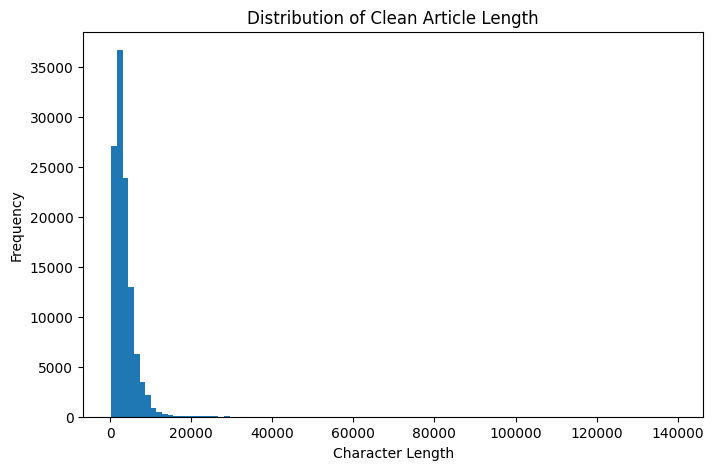

In [77]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))
plt.hist(df_final_clean["clean_len"], bins=100)
plt.title("Distribution of Clean Article Length")
plt.xlabel("Character Length")
plt.ylabel("Frequency")
plt.show()

In [78]:
df_final_clean["domain"].value_counts().head(20)

domain
www.einpresswire.com            3414
menafn.com                      3403
www.prnewswire.com              2471
www.mexc.co                     2139
www.mexc.com                    1419
www.globenewswire.com           1127
www.forbes.com                  1006
www.webpronews.com               921
www.mexc.fm                      840
www.business-standard.com        814
economictimes.indiatimes.com     790
www.nasdaq.com                   787
www.geeky-gadgets.com            740
www.devdiscourse.com             731
timesofindia.indiatimes.com      685
www.livemint.com                 643
www.benzinga.com                 639
finance.yahoo.com                618
www.newsbreak.com                617
www.channelnewsasia.com          617
Name: count, dtype: int64

In [79]:
def remove_title_prefix(text, title):
    if not isinstance(text, str):
        return text

    if not isinstance(title, str):
        return text

    text_strip = text.strip()
    title_strip = title.strip()

    if text_strip.lower().startswith(title_strip.lower()):
        return text_strip[len(title_strip):].strip()

    return text_strip

In [80]:
# Build the final inspection dataset
news_df = df_final_clean[
    ["url", "domain", "date", "title", "text_clean", "clean_len"]
].copy()

# Create a stable document id
news_df = news_df.reset_index(drop=True)
news_df["doc_id"] = news_df.index

# Create a body-only text field for inspection/reporting
news_df["clean_doc_text"] = news_df.apply(
    lambda r: remove_title_prefix(r["text_clean"], r["title"]),
    axis=1
)


news_df = news_df[
    ["doc_id", "url", "domain", "date", "title", "clean_doc_text", "clean_len"]
].copy()

news_df.head()

,doc_id,url,domain,date,title,clean_doc_text,clean_len
0,0,https://boingboing.net/2024/07/01/this-ai-vide...,boingboing.net,2024-07-01,This AI video of gymnastics might be the freak...,Thumbnails : Youtube Thumbnail generator\nThis...,2615
1,1,https://boingboing.net/2024/09/18/if-using-ai-...,boingboing.net,2024-09-22,"If using AI feels like a chore, try this - Boi...",Thumbnails : Youtube Thumbnail generator\nIf u...,3767
2,2,https://clickup.com/ai/prompts/business-risk-m...,clickup.com,2024-03-13,Best AI Prompts for Business Risk Management,Harness the power of ClickUp AI to make smarte...,2403
3,3,https://crooksandliars.com/2025/12/state-ags-w...,crooksandliars.com,2025-12-15,State AGs Warn AI Companies: Clean Up Your Chi...,'Deranged Person': Trump Doubles Down By Calli...,3833
4,4,https://dbtnews.com/2023/07/26/bullfrog-ai-hol...,dbtnews.com,2023-07-26,Bullfrog AI Holdings Inc. [BFRG] Revenue clock...,Bullfrog AI Holdings Inc. [BFRG] Revenue clock...,2266


In [81]:
def print_document(record, text_chars=1200):
    print("=" * 120)
    print(f"Document #{record['doc_id']}")
    print("-" * 120)

    print(f"doc_id : {record['doc_id']}")
    print(f"url    : {record['url']}")
    print(f"domain : {record['domain']}")
    print(f"date   : {record['date']}")
    print(f"title  : {record['title']}")
    print()

    print(f"CLEAN_DOC_TEXT (first {text_chars} chars)")
    print("-" * 120)

    text = str(record["clean_doc_text"])
    print(text[:text_chars])
    print()

In [82]:
sample_docs = news_df.sample(10, random_state=42)

for _, row in sample_docs.iterrows():
    print_document(row, text_chars=1200)

Document #105694
------------------------------------------------------------------------------------------------------------------------
doc_id : 105694
url    : https://www.engadget.com/general/tsmc-will-reportedly-stop-making-advanced-ai-chips-for-chinese-companies-143029506.html
domain : www.engadget.com
date   : 2024-11-08 00:00:00
title  : TSMC will reportedly stop making advanced AI chips for Chinese companies

CLEAN_DOC_TEXT (first 1200 chars)
------------------------------------------------------------------------------------------------------------------------
The company denied any working relationship with Huawei and also stopped selling its chips to the client it believes had been illegally forwarding them to the Chinese brand. The Times' sources said that TSMC made the decision to suspend the production of AI chips for Chinese clients altogether, because it wants to show the US government that it's "not acting against US interests." Its new policy could have a big impact 

Manual inspection suggests that the cleaning pipeline successfully preserves the main article body for the majority of documents while removing most navigation, UI, and error-page noise. A small number of residual artifacts remain, mainly in the form of footer recommendations, category headers, and occasional aggregation-style pages. These are common in large-scale crawled news corpora and were judged not to materially affect downstream NLP analysis.